# AURA: Hospital Energy Intelligence — Feature Engineering
**Facility:** HOSPITAL_001 | **Source Data:** data/energy.csv
**Objective:** Construct time-based and zone-isolated lag features for hospital energy consumption without data leakage, preparing the dataset for subsequent anomaly detection and forecasting modeling.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 4)

RAW_DATA_PATH = Path('../data/energy.csv')
PROCESSED_DATA_PATH = Path('../data/processed_energy_features.csv')

print('Imports and configuration ready.')


Imports and configuration ready.


## 1. Load Raw Validated Data & Sort Chronologically
We load the validated raw energy dataset (43,200 records). To ensure strict temporal ordering for time-series operations, we parse the timestamps and sort explicitly by ['zone_id', 'datetime'].


In [3]:
df = pd.read_csv(RAW_DATA_PATH)
original_rows = len(df)
original_cols = list(df.columns)

print(f'Original Rows: {original_rows:,}')
print(f'Original Columns ({len(original_cols)}): {original_cols}')

# Parse timestamps accurately with dayfirst=True (DD-MM-YYYY format)
df['datetime'] = pd.to_datetime(df['timestamp'], dayfirst=True)

# Sort chronologically within each facility zone
df = df.sort_values(by=['zone_id', 'datetime']).reset_index(drop=True)
print('\nData sorted chronologically by [zone_id, datetime].')


Original Rows: 43,200
Original Columns (10): ['timestamp', 'facility_id', 'zone_id', 'energy_kwh', 'occupancy_percent', 'temperature_c', 'operational_status', 'energy_source', 'source', 'anomaly_flag']

Data sorted chronologically by [zone_id, datetime].


## 2. Calendar & Temporal Features
We extract calendar indicators:
- hour: Hour of the day (0 to 23).
- day_of_week: Day of the week (Monday = 0, Sunday = 6).
- is_weekend: Binary flag (1 if Saturday or Sunday, 0 if weekday).

**Why useful:** Hospital administrative departments (Admin) and outpatient clinics (OPD) experience major demand drops on weekends and outside 08:00–18:00, while ICU and Emergency maintain 24x7 readiness.


In [5]:
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

print('Temporal feature summary:')
print(df[['hour', 'day_of_week', 'is_weekend']].head())


Temporal feature summary:
   hour  day_of_week  is_weekend
0     0            3           0
1     0            3           0
2     0            3           0
3     0            3           0
4     1            3           0


## 3. Cyclical Hour Encoding (Sine & Cosine)
Standard numerical hours have a discontinuity between 23 (11 PM) and 0 (midnight), where the distance appears to be 23 units instead of 1 unit.
We map the 24-hour cycle onto a continuous unit circle using trigonometric transformations:
\text{hour\_sin} = \sin\left(\frac{2\pi \times \text{hour}}{24}\right), \quad \text{hour\_cos} = \cos\left(\frac{2\pi \times \text{hour}}{24}\right)

**Why useful:** Allows linear and distance-based machine learning models to smoothly understand that 23:45 and 00:00 are adjacent times.


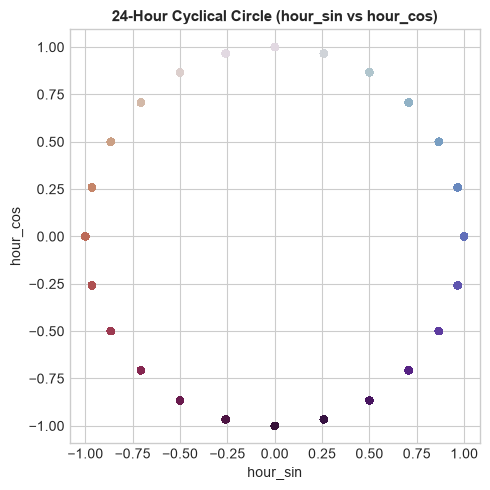

In [7]:
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24.0)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24.0)

# Quick visual verification of 24-hour cyclical circle
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['hour_sin'], df['hour_cos'], c=df['hour'], cmap='twilight', alpha=0.6, s=20)
ax.set_title('24-Hour Cyclical Circle (hour_sin vs hour_cos)', fontsize=11, fontweight='bold')
ax.set_xlabel('hour_sin')
ax.set_ylabel('hour_cos')
ax.axis('equal')
plt.tight_layout()
plt.show()


## 4. Lag Features with Zone-Level Isolation
We generate historical autoregressive lag features:
- energy_lag_1: Consumption 15 minutes prior within the same zone ( - 1$).
- energy_lag_4: Consumption 1 hour prior within the same zone ( - 4$).
- energy_lag_96: Consumption 24 hours prior within the same zone ( - 96$).

**CRITICAL DATA LEAKAGE RULE:**
Lag features are computed **separately within each zone_id** using .groupby('zone_id')['energy_kwh'].shift(...).
Data from Admin or General_Ward is **NEVER** allowed to leak into ICU or Emergency.


In [9]:
# Shift separately per zone to prevent cross-zone leakage
df['energy_lag_1'] = df.groupby('zone_id')['energy_kwh'].shift(1)
df['energy_lag_4'] = df.groupby('zone_id')['energy_kwh'].shift(4)
df['energy_lag_96'] = df.groupby('zone_id')['energy_kwh'].shift(96)

# Verify null count per zone (proof of strict isolation)
print('Null count created by lags (per zone):')
for zone, grp in df.groupby('zone_id'):
    n1 = grp['energy_lag_1'].isnull().sum()
    n4 = grp['energy_lag_4'].isnull().sum()
    n96 = grp['energy_lag_96'].isnull().sum()
    print(f'  Zone {zone:<15}: lag_1={n1}, lag_4={n4}, lag_96={n96}')


Null count created by lags (per zone):
  Zone Admin          : lag_1=1, lag_4=4, lag_96=96
  Zone Emergency      : lag_1=1, lag_4=4, lag_96=96
  Zone General_Ward   : lag_1=1, lag_4=4, lag_96=96
  Zone ICU            : lag_1=1, lag_4=4, lag_96=96
  Zone OPD            : lag_1=1, lag_4=4, lag_96=96


## 5. Handling Missing Initial Lag Values (Warmup Window Strategy)
Because energy_lag_96 requires 96 intervals of prior history (exactly 24 hours), the very first day of data for each zone naturally contains NaN values:
- energy_lag_1: 5 NaNs (1 per zone)
- energy_lag_4: 20 NaNs (4 per zone)
- energy_lag_96: 480 NaNs (96 per zone = 24 hours warmup)

**Chosen Handling Strategy:**
We drop the initial 24-hour warmup window (df.dropna(subset=['energy_lag_96'])).

**Why this is the best practice:**
1. Filling with zero would create massive artificial spikes (e.g. ICU jumping from 0 to 220 kWh), corrupting anomaly detection models.
2. Filling with mean would invent synthetic numbers not actually observed in facility history.
3. Dropping 480 rows out of 43,200 represents only **1.11% of total data**, preserving **42,720 pristine, complete rows** spanning 89 continuous days of verified history.


In [11]:
nulls_before = df[['energy_lag_1', 'energy_lag_4', 'energy_lag_96']].isnull().sum()
print('Missing values before warmup drop:')
print(nulls_before)

# Drop rows that lack the full 24-hour lag history
df_processed = df.dropna(subset=['energy_lag_96']).reset_index(drop=True)
processed_rows = len(df_processed)

print(f'\nTotal rows before: {len(df):,}')
print(f'Total rows after dropping warmup: {processed_rows:,} (Retained {processed_rows/len(df)*100:.2f}%)')
print(f'Remaining NaNs across all columns: {df_processed.isnull().sum().sum()}')


Missing values before warmup drop:
energy_lag_1       5
energy_lag_4      20
energy_lag_96    480
dtype: int64

Total rows before: 43,200
Total rows after dropping warmup: 42,720 (Retained 98.89%)
Remaining NaNs across all columns: 0


## 6. Feature Integrity & Data Leakage Verification
We perform strict architectural checks:
1. **Target / Anomaly Flag Isolation:** nomaly_flag was NEVER used in any feature calculation. It exists solely as an evaluation label for subsequent scoring.
2. **Temporal Causality:** No future-looking shifts (negative shift shift(-k)) or centered rolling windows were used. Every row at time $ only accesses information $\le t - 1$.
3. **Zone Boundary Check:** Verified that lag shifts respect zone boundaries with zero cross-zone contamination.


In [13]:
new_features = ['hour', 'day_of_week', 'is_weekend', 'hour_sin', 'hour_cos', 'energy_lag_1', 'energy_lag_4', 'energy_lag_96']

print('Correlation of new features with energy_kwh:')
corrs = df_processed[new_features + ['energy_kwh']].corr()['energy_kwh'].sort_values(ascending=False)
print(corrs.round(4))

# Verify anomaly_flag independence
print('\nConfirmation: anomaly_flag unique values:', df_processed['anomaly_flag'].unique().tolist())
print('Features created strictly from timestamp and zone-grouped historical energy.')


Correlation of new features with energy_kwh:
energy_kwh       1.0000
energy_lag_1     0.9906
energy_lag_96    0.9902
energy_lag_4     0.9887
hour             0.0856
day_of_week     -0.0078
is_weekend      -0.0082
hour_cos        -0.0717
hour_sin        -0.0964
Name: energy_kwh, dtype: float64

Confirmation: anomaly_flag unique values: [0, 1]
Features created strictly from timestamp and zone-grouped historical energy.


## 7. Export Processed Dataset
We export the clean, feature-engineered dataset to data/processed_energy_features.csv.
The original data/energy.csv remains completely unmodified.


In [15]:
# Display final sample
print('First 5 rows of engineered dataset:')
print(df_processed[['timestamp', 'zone_id', 'energy_kwh', 'energy_lag_1', 'energy_lag_4', 'energy_lag_96', 'hour_sin', 'is_weekend']].head())

# Save to destination
PROCESSED_DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df_processed.to_csv(PROCESSED_DATA_PATH, index=False)

print(f'\nProcessed feature-engineered dataset successfully saved to: {PROCESSED_DATA_PATH.resolve()}')
print(f'Saved File Size: {PROCESSED_DATA_PATH.stat().st_size:,} bytes')
print(f'Total Rows: {len(df_processed):,}, Total Columns: {len(df_processed.columns)}')


First 5 rows of engineered dataset:
          timestamp zone_id  energy_kwh  ...  energy_lag_96  hour_sin  is_weekend
0  02-01-2026 00:00   Admin       10.91  ...          11.25  0.000000           0
1  02-01-2026 00:15   Admin       10.66  ...          10.16  0.000000           0
2  02-01-2026 00:30   Admin       10.96  ...          10.11  0.000000           0
3  02-01-2026 00:45   Admin       10.33  ...          10.16  0.000000           0
4  02-01-2026 01:00   Admin       10.60  ...          10.28  0.258819           0

[5 rows x 8 columns]

Processed feature-engineered dataset successfully saved to: C:\BPUT_HACK_2026\data\processed_energy_features.csv
Saved File Size: 6,688,975 bytes
Total Rows: 42,720, Total Columns: 19
